# Fig. 7c: neural manifold of the ground truth (evoked model)

**author**: laquitainesteeve@gmail.com

**purpose**: reproduce panel c of the paper: the 3D PCA manifold of the responses of all ground truth neurons to the 360 stimulus directions, one point per trial. It is the reference of panels d (random undersampling to the yield of Kilosort 4) and e (undersampling and selection biases of Kilosort 4). Source data and svg are saved in figures/8_source_data/fig7c/.

**method (as in the paper's notebook fig7_A_pca_manifolds_revised.ipynb, same data and analysis as the ground truth of fig7a.ipynb)**
* 1-hour biophysical simulation of the evoked regime (20 kHz): 360 directions x 50 repeated trials of 200 ms; response of a neuron to a trial: its spike count in the stimulus window; responses of the 1,836 ground truth neurons x 18,000 trials
* PCA of the trials with 3 components, coordinates divided by the largest absolute coordinate; colour: stimulus direction (hsv colormap)

In [1]:
%load_ext autoreload
%autoreload 2
import os
import numpy as np
import pandas as pd
import spikeinterface as si
from matplotlib import pyplot as plt
import warnings
warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", category=UserWarning)

# set project path
PROJ_PATH = "/home/steeve/steeve/epfl/code/spikebias/"
os.chdir(PROJ_PATH)

# custom package
from sklearn.decomposition import PCA
from src.nodes.task import task

# paths
GT_PATH = "dataset/00_raw/ground_truth_npx_evoked"

# stimulus: 360 directions x 50 repeated trials
SAMPLE_DIR = np.arange(0, 360, 1)

# FIGURE SETTINGS
plt.rcParams["font.family"] = "Arial"
plt.rcParams["font.size"] = 6  # 5-7 with Nature neuroscience as reference
plt.rcParams["lines.linewidth"] = 0.5
plt.rcParams["axes.linewidth"] = 0.5
plt.rcParams["axes.spines.top"] = False
plt.rcParams["xtick.major.width"] = 0.5
plt.rcParams["xtick.minor.width"] = 0.5
plt.rcParams["ytick.major.width"] = 0.5
plt.rcParams["ytick.minor.width"] = 0.5
plt.rcParams["xtick.major.size"] = 3.5 * 1.1
plt.rcParams["xtick.minor.size"] = 2 * 1.1
plt.rcParams["ytick.major.size"] = 3.5 * 1.1
plt.rcParams["ytick.minor.size"] = 2 * 1.1
legend_cfg = {"frameon": False, "handletextpad": 0.5}

# save config
savefig_cfg = {"transparent": True, "dpi": 300}

## Ground truth responses to the stimulus directions

In [2]:
%%time

# trials of the 360 directions and their direction labels
trial = task.get_direction_trials(SAMPLE_DIR)
direction = task.get_stimulus_labels()[trial].astype(float)

# task epochs (ms)
task_pm = task.get_task_parameters(start_delay=500, n_orientations=10, n_repeats=50, stimulus_duration=200, n_simulations=36)
stimulus_intervals_ms = task.get_stimulus_intervals_ms(task_pm["epoch_labels"], task_pm["epoch_ms"])

# neurons x trials spike counts
SortingTrue = si.load_extractor(GT_PATH)
response = task.compute_response_by_stim_matrix(SortingTrue.unit_ids, SortingTrue, stimulus_intervals_ms)[:, trial]
print("ground truth neurons:", response.shape[0], "| trials:", response.shape[1])

ground truth neurons: 1836 | trials: 18000
CPU times: user 14 s, sys: 116 ms, total: 14.1 s
Wall time: 14.1 s


## 3D PCA manifold

In [3]:
%%time

manifold = PCA(n_components=3, random_state=0).fit_transform(response.T)
manifold = manifold / np.max(np.abs(manifold))
df = pd.DataFrame({"trial": np.arange(len(direction)), "direction_deg": direction, "latent_1": manifold[:, 0], "latent_2": manifold[:, 1], "latent_3": manifold[:, 2]})
display(df.head(3))

,trial,direction_deg,latent_1,latent_2,latent_3
0,0,0.0,-0.206169,-0.490573,0.516363
1,1,0.0,-0.353069,-0.197470,0.142902
2,2,0.0,-0.361730,-0.200738,0.180464


CPU times: user 566 ms, sys: 18 ms, total: 584 ms
Wall time: 584 ms


## Plot, same as the paper's panel c

In [4]:
def draw_latent_axes(fig, ax, labels=False, size=1.0, rect=None):
    """latent axes drawn as in the paper: three arrows from a common origin at the lower left of the manifold (up: latent 3, up-right: latent 2,
    down-right: latent 1). The arrows are drawn in the axes coordinates, on a transparent overlay"""
    pos = rect if rect is not None else ax.get_position()
    overlay = fig.add_axes([pos.x0, pos.y0, pos.width, pos.height], facecolor="none")
    overlay.set_xlim(0, 1); overlay.set_ylim(0, 1); overlay.axis("off")
    x0, y0 = 0.03, 0.14
    arrow = dict(arrowstyle="-|>,head_length=0.5,head_width=0.22", color="k", linewidth=1.0, shrinkA=0, shrinkB=0)
    tips = {"Latent 3": (0, 0.14), "Latent 2": (0.18, 0.075), "Latent 1": (0.18, -0.07)}
    for name, (dx, dy) in tips.items():
        overlay.annotate("", xy=(x0 + size * dx, y0 + size * dy), xytext=(x0, y0), arrowprops=arrow)
    if labels:
        overlay.text(x0 + 0.01, y0 + size * 0.15, "Latent 3", ha="left", va="bottom", fontsize=5.5)
        overlay.text(x0 + size * 0.19, y0 + size * 0.08, "Latent 2", ha="left", va="center", fontsize=5.5)
        overlay.text(x0 + size * 0.19, y0 - size * 0.075, "Latent 1", ha="left", va="center", fontsize=5.5)
    return overlay

def plot_source_data(df: pd.DataFrame):
    """3D manifold of the ground truth (one point per trial); colour: stimulus direction; latent axes as in the paper"""

    fig = plt.figure(figsize=(1.7, 1.5))
    ax = fig.add_subplot(1, 1, 1, projection="3d")
    ax.view_init(20, 45, 0)
    ax.scatter(df["latent_1"], df["latent_2"], df["latent_3"], c=df["direction_deg"], cmap="hsv", edgecolors="w", linewidths=0.2, s=6, rasterized=True)
    ax.set_xlim(df["latent_1"].min(), df["latent_1"].max()); ax.set_ylim(df["latent_2"].min(), df["latent_2"].max()); ax.set_zlim(df["latent_3"].min(), df["latent_3"].max())
    ax.set_axis_off(); ax.set_box_aspect((1, 1, 0.75), zoom=1.2)
    draw_latent_axes(fig, ax)
    ax.set_title("Ground truth", fontsize=6, pad=-2)
    return fig, ax

## Plot and save the figure and the source data

CPU times: user 1.12 s, sys: 20 ms, total: 1.14 s
Wall time: 1.13 s


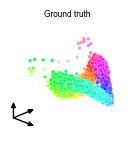

In [5]:
%%time

# plot
fig, ax = plot_source_data(df)

# save figure
os.makedirs("figures/8_source_data/fig7c", exist_ok=True)
plt.savefig("figures/8_source_data/fig7c/fig7c.svg", bbox_inches="tight", **savefig_cfg)

# save source data
df.to_excel("figures/8_source_data/fig7c/fig7c.xlsx", index=False)

## Check: replot from the saved source data

CPU times: user 363 ms, sys: 2.99 ms, total: 366 ms
Wall time: 366 ms


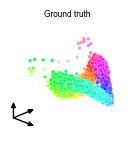

In [6]:
%%time

df = pd.read_excel("figures/8_source_data/fig7c/fig7c.xlsx")
fig, ax = plot_source_data(df)